# Decision Tree on TF-IDF

This notebook trains a single decision tree on the same TF-IDF features and train/test split as the Logistic Regression baseline. A shallow tree can be read in full, which makes it a useful contrast to the Random Forest. It also lets us test the explanation methods: we know the tree's real rules, so we can check whether the methods report them correctly.

Because the tree can be read directly, PDP, ICE and SP-LIME are not used (see the note before Section 8). The steps are global importance (PFI, TreeSHAP), then individual decisions (LIME, SHAP).

## 1. Setup

In [1]:
import os, sys
if not os.path.exists("preprocessing.py"):                             
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))  
sys.path.insert(0, os.getcwd())                                      

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


Same TF-IDF settings as the baseline (see its Section 4). This cell only shows the size of the matrix; the TF-IDF the model uses is fitted again in the next step, on the training articles only.

## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


## 6. Train Decision Tree

We use a single decision tree limited to a depth of 3, with at least 50 training articles in every leaf, so that no rule rests on a handful of chance cases. A tree of this size has at most 7 decision points and 8 leaves, in line with the 7 ± 2 limit on human working memory, so a reader can follow any prediction from the top question to its answer and can hold the whole tree in mind at once. This matters when the model is audited, because the model should stay simulatable: an auditor can take an article, answer each question in turn, reach the same prediction the model made, and check every rule for anything unreasonable. A deeper tree quickly makes this impossible, since the size of a tree roughly doubles with each extra level. A depth of 5 allows up to 31 decision points, a depth of 7 up to 127, and a depth of 10 up to 1,023, which is far more than a person can read, remember or check, even though each single prediction would still follow a path of only 5, 7 or 10 questions. The cost of choosing a depth of 3 is flexibility: the tree can only ask a few questions, so it can use only a handful of the 5,000 terms.

In [7]:
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

### 6.1 The Tree Itself

Unlike the Random Forest, the whole model fits on one page. The text version and the diagram below show every question the tree asks and what it predicts at the end. In each box, the first line is the question asked of an article (the TF-IDF weight of a term compared with a cutoff), and the box also shows the share of training articles that reached it and the class predicted there.

In [8]:
used_idx = np.unique(dt.tree_.feature[dt.tree_.feature >= 0])
print("Terms used by the tree:", list(feature_names[used_idx]))
print()
print(export_text(dt, feature_names=list(feature_names), decimals=3))

Terms used by the tree: ['ministry', 'reuters', 'said', 'via', 'video']

|--- via <= 0.000
|   |--- said <= 0.025
|   |   |--- video <= 0.003
|   |   |   |--- class: 1
|   |   |--- video >  0.003
|   |   |   |--- class: 1
|   |--- said >  0.025
|   |   |--- video <= 0.022
|   |   |   |--- class: 0
|   |   |--- video >  0.022
|   |   |   |--- class: 1
|--- via >  0.000
|   |--- reuters <= 0.012
|   |   |--- ministry <= 0.010
|   |   |   |--- class: 1
|   |   |--- ministry >  0.010
|   |   |   |--- class: 0
|   |--- reuters >  0.012
|   |   |--- said <= 0.041
|   |   |   |--- class: 1
|   |   |--- said >  0.041
|   |   |   |--- class: 0



The tree uses five terms (via, said, video, reuters and ministry) and asks at most three questions per article. A cutoff of 0.000 for via just means "does the article contain via at all?"

The rules:

- **No via:** if the article has little or no said, the tree predicts fake. If it uses said more, it predicts real, unless video is also present.
- **Has via:** the tree predicts fake, with two exceptions. It predicts real if the article also contains ministry (and not reuters), or if it contains reuters and uses said often.

The video question on the left (cutoff 0.003) never changes the answer, because both of its leaves predict fake. It only changes how confident the tree is. said and video are each asked twice with different cutoffs, so the tree uses all 7 decision points and 8 leaves that a depth of 3 allows.

Three of the five terms are source fingerprints: via comes from the photo credit "Featured image via Getty Images," video from fake sites that embed videos, and reuters is the publisher's name. said is Reuters' reporting style, and ministry is common in international news. So the tree's very first question is about a photo credit, not about anything the article claims.

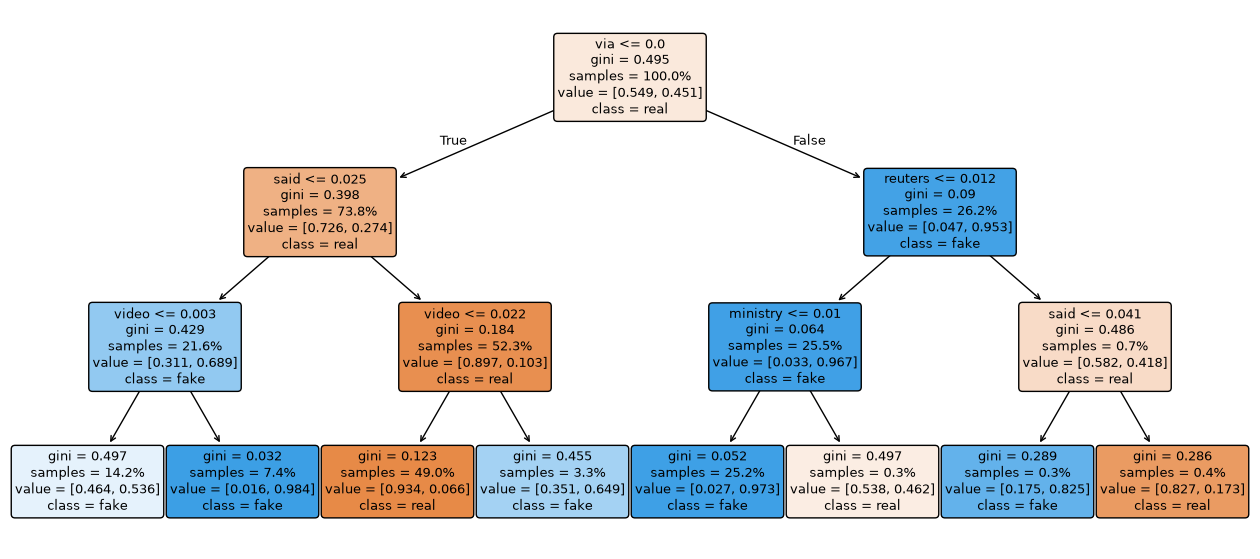

In [9]:
plt.figure(figsize=(16, 7))
plot_tree(dt, feature_names=list(feature_names), class_names=["real", "fake"],
          filled=True, rounded=True, proportion=True, fontsize=9, precision=3)
plt.show()

Each box shows the question, the share of training articles that reach it (samples), the real/fake mix among them (value, real first), and the predicted class. Gini runs from 0 (one class only) to 0.5 (an even split). Orange leans real, blue leans fake, and darker means a stronger lean. The root is 54.9% real and 45.1% fake.

The first split already does most of the work. 26.2% of articles contain via, and 95.3% of them are fake. Almost all of these (25.2% of all articles) end in one leaf that is 97.3% fake. On the other side, the biggest leaf holds articles with no via, more said and little or no video: 49.0% of all articles, 93.4% of them real.

The weakest leaf is the one for articles with no via, little or no said and no video (14.2% of articles). It is 53.6% fake and 46.4% real, so predicting fake there is close to a coin flip. The three small leaves in the via branch hold about 1% of articles between them and barely matter.

### 6.2 Why Not a Deeper Tree?

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for depth in [3, 5, 7, 10]:
    cv_model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE)
    cv_pred = cross_val_predict(cv_model, X_train, y_train, cv=skf)
    rows.append({
        "max_depth": depth,
        "max_splits": 2**depth - 1,
        "max_leaves": 2**depth,
        "cv_accuracy": round(accuracy_score(y_train, cv_pred), 3),
    })
pd.DataFrame(rows)

,max_depth,max_splits,max_leaves,cv_accuracy
0,3,7,8,0.879
1,5,31,32,0.920
2,7,127,128,0.937
3,10,1023,1024,0.943


Deeper trees are clearly better: cross-validated accuracy goes from 0.879 at depth 3 to 0.920, 0.937 and 0.943 at depths 5, 7 and 10. Depth 3 gives up about 6 points compared with depth 10, and even depth 10 stays below the baseline logistic regression (0.980).

That is the cost of readability. A depth-10 tree can have over 1,000 decision points, which nobody can check by hand. We keep depth 3 because the point of this notebook is a model we can read in full.

## 7. Validate Predictive Performance

In [11]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, dt.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.93      0.85      0.89      4238
        fake       0.83      0.92      0.88      3489

    accuracy                           0.88      7727
   macro avg       0.88      0.89      0.88      7727
weighted avg       0.89      0.88      0.88      7727

Fake-class recall (test):  0.9229
Fake-class recall (train): 0.9236
Accuracy (test): 0.8825
Share of test articles predicted fake: 0.499


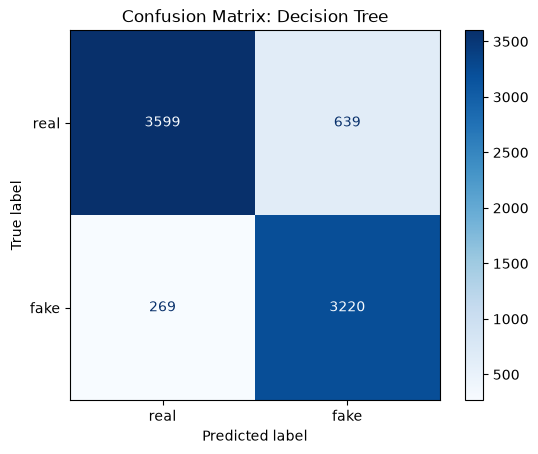

In [12]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Decision Tree")
plt.show()

- True Positive, correctly caught fake news article: 3,220
- False Negative, fake news article predicted as real: 269
- False Positive, real article predicted as fake: 639
- True Negative, correctly identified real article: 3,599

The tree catches 92.3% of fake articles (recall = 0.9229), but only 83.4% of its "fake" flags are right (precision = 0.834). Accuracy is 88.3%, well above the 54.8% of always predicting "real" but almost 10 points below the baseline (0.980). It misses more fake articles than the baseline (269 vs 108) and raises far more false alarms (639 vs 44).

Training and test recall are almost the same (0.9236 vs 0.9229), so the tree isn't overfitting. It is simply too simple.

The diagram shows where the errors come from. Most false alarms come from the coin-flip leaf (no via, little said, no video), which predicts fake for every article in it. Most missed fakes come from the big real leaf: fake articles that use said often and have no photo credit or video. To this tree, a fake article that quotes people like a news report looks real.

In [13]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx] 

The tree is fully readable: for any article, we can follow its path through the rules in Section 6.1 and see exactly why it got its prediction. No post-hoc method can do better than that.

So PDP, ICE and SP-LIME are left out. Each term only matters at one or two cutoffs, so its PDP would be a step or two and each ICE curve a step or a flat line, all of which can already be read from the tree. SP-LIME picks a few representative articles to summarise a model we can't read, but here the 8 leaves already are that summary.

PFI, TreeSHAP and LIME are still useful, because they show what the tree doesn't: how much each question matters on real articles. PFI measures the effect on Fake-class recall, and TreeSHAP the effect on the predicted probability.

Since we know the true rules, this is also a test of the methods. If they report the tree correctly, we can trust them more on the Random Forest, whose rules we can't read.

## 8. Global Importance (PFI and TreeSHAP)

Across the whole test set, which of the tree's five terms matter most, and how much?

### 8.1 Permutation Feature Importance (PFI)

Each of the five terms used by the tree is shuffled across the test articles, and we measure how much Fake-class recall drops, averaged over 5 repeats. Shuffling any other term cannot change a prediction, so those terms are left out.

A large drop means the tree relies on that term to catch fake articles. A drop near zero means the term barely affects recall. A negative drop means recall improves when the term is shuffled, so the rule it is part of does not help on the test set.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(dt, X_test_dense, y_test, used_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.9229


,term,mean_recall_drop,std
2,said,0.084781,0.001956
3,via,0.051648,0.002863
0,ministry,0.027286,0.001896
4,video,0.021840,0.001789
1,reuters,0.012038,0.001729


Every term matters. Shuffling said lowers recall by 0.085, about 296 of the 3,489 fake test articles, and via by 0.052, about 180 articles. ministry (0.027), video (0.022) and reuters (0.012) follow. Every standard deviation is under 0.003, so all five effects are clearly real.

ministry ranks third, even though its own leaf holds only 0.3% of articles. Shuffling gives ministry to about 5% of articles at random, including fake articles that contain via. Those articles are sent to the small ministry leaf, which predicts real, so they are missed. PFI measures how much the tree's decisions depend on a term, which is not the same as how often the term decides a real article.

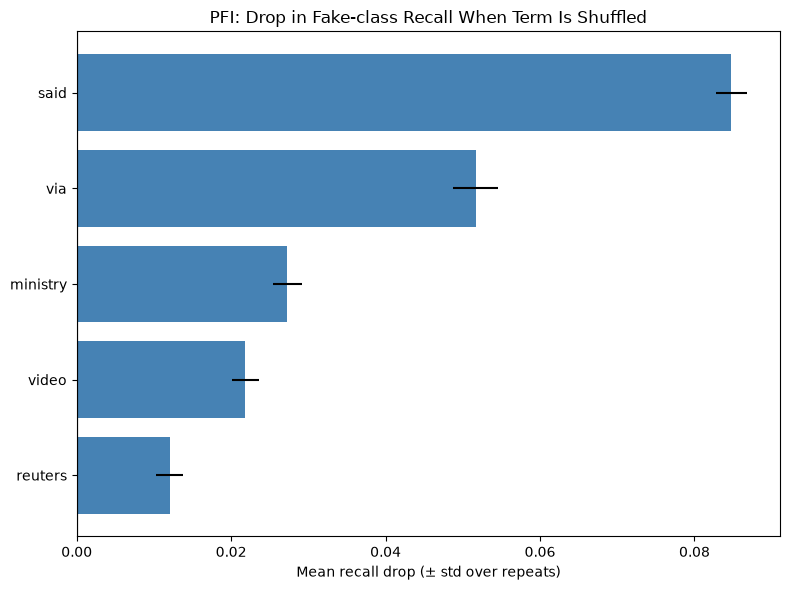

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The plot shows the same picture. Every bar is well above zero with a narrow error bar. said and via stand clearly apart from the rest. They are the two questions every article passes through: via is the first question, and said is the second for the 73.8% of articles without via. The terms asked later, about smaller groups of articles, matter less.

### 8.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term. Starting from the tree's average predicted probability of fake, the contributions add up exactly to the probability the tree gives that article. For trees, TreeSHAP calculates these values exactly rather than estimating them.

The values are computed for 200 test articles, the same sample size used in the other notebooks, and then averaged to show which terms matter most overall.

In [16]:
explainer_shap = shap.TreeExplainer(dt)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 5000)


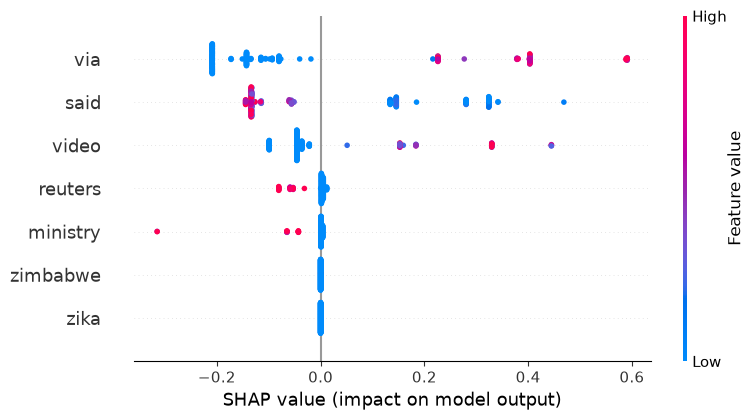

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

Each dot is one of the 200 test articles. Its position shows how far a term moved that article's probability of fake away from the average of 0.451, and its color shows the term's weight (red high, blue low or absent). Only the tree's five terms have any spread. The last two rows are unused terms that the plot adds to fill seven rows, and their values are all exactly zero, as for every unused term. So TreeSHAP reports the tree correctly.

The directions match the rules. Articles with via are pushed toward fake by 0.37 on average (up to 0.59), and articles without it are pushed toward real by 0.16, so via matters even when it's missing. said works the other way: articles without it are pushed toward fake by 0.23 on average. video pushes toward fake when present (+0.25 on average), and reuters and ministry push slightly toward real in the few articles that contain them.

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
4789,via,0.221642
3905,said,0.170735
4793,video,0.093653
3801,reuters,0.009600
2853,ministry,0.008410
23,accepted,0.000000
4984,yield,0.000000


On average, via moves the probability the most (0.22), then said (0.17) and video (0.09). reuters and ministry move it by less than 0.01, and every other term is exactly zero.

The order differs from PFI, where said was first and ministry third, because the two measure different things. SHAP averages how much a term changes the probability across the sample, so rare terms like reuters and ministry get small averages. PFI measures how much recall drops when a term's values are shuffled, which can push fake articles down rare branches, as happened with ministry. Both agree on the main point: via and said drive most of the tree's decisions, and via is a source fingerprint.

## 9. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the tree's predictions overall. Now we look at three single articles to see why the tree made each decision:

- a fake article the tree caught correctly,
- a fake article it missed, and
- a real article it wrongly flagged as fake.

LIME and SHAP show which words pushed each prediction toward fake or toward real. Since the tree's own path already explains each article exactly, this also lets us check whether LIME and SHAP report that path correctly.

In [19]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return dt.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = dt.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 9.1 LIME: Word-Removal Sanity Checks

LIME removes words from one article and watches how the predicted probability changes. Three cases are inspected: a correctly caught fake article (TP), a missed fake article (FN), and a real article wrongly flagged as fake (FP). Weights are for the fake class: positive = pushes toward fake.

True Positive (fake, caught) | P(fake) = 0.984


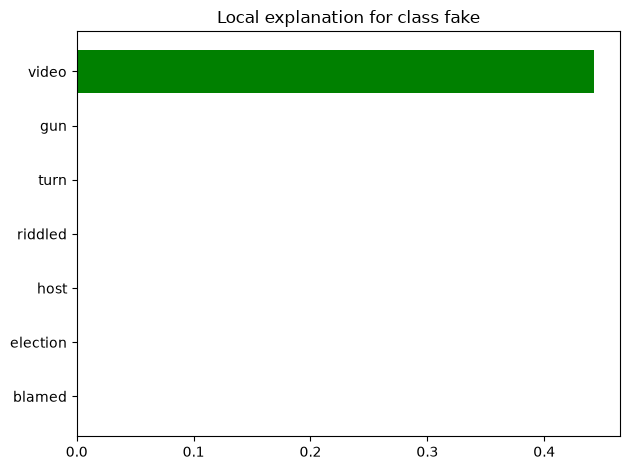

False Negative (fake, missed) | P(fake) = 0.066


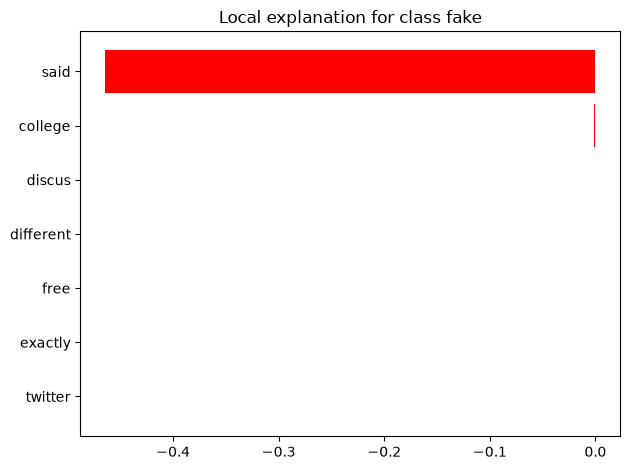

False Positive (real, flagged) | P(fake) = 0.984


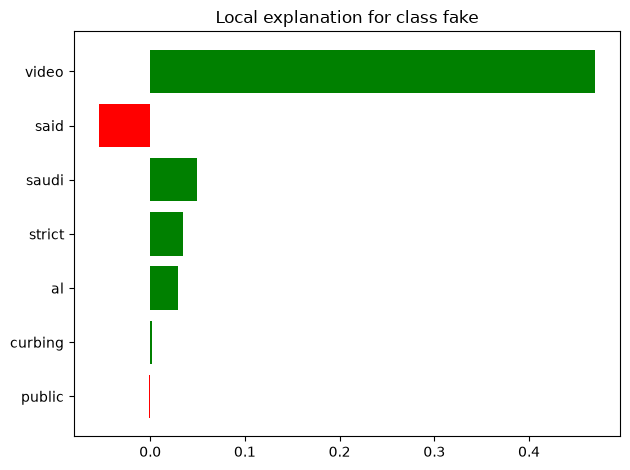

In [20]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

**True Positive (P(fake) = 0.984).** The fake article ("CNN HOST To Jill Stein: …") has no via and no said, but it does contain video, so it lands in the leaf that is 98.4% fake. LIME shows video (0.44) as the only word that matters; every other word is below 0.002. That matches the tree: this article's path depends on one word.

**False Negative (P(fake) = 0.066).** The fake article ("ILLEGAL ALIEN COLLEGE STUDENTS Protest For A Freebie You Won't Believe!") uses said often enough to pass the cutoff and has no via or video, so it ends up in the big leaf that is 93.4% real. LIME shows said (−0.47) as the only reason for the miss. Any reader would spot the sensational headline, but the tree never looks at it.

**False Positive (P(fake) = 0.984).** This real article ("Saudi Shura Council to vote on curbing autonomy of morality police") reaches the same leaf as the True Positive. It contains video, and its said weight (0.016) is just under the 0.025 cutoff. LIME again shows video (0.47) as the main reason. The tree is exactly as confident here as for the correct case, and both times it rests on one word.

LIME also gives small weights to saudi, strict and al, which the tree never uses. Removing a word raises the TF-IDF weights of the words left behind, so removing these can push said over its cutoff. Those small bars come from TF-IDF normalisation, not from the tree's rules.

A note on these examples: the True Positive and False Positive were picked as the most extreme cases, and both fall in a small leaf (7.4% of training articles). The missed fake is more typical. It sits in the big real leaf, where most missed fakes end up: articles that use said and have no photo credit or video. LIME can show why such an article was missed (said), but not the effect of a word that isn't there, like via. For these cases the tree diagram is the clearer explanation.

### 9.2 SHAP Waterfall (the missed fake article)

LIME approximates the tree around one article, while SHAP splits the tree's own prediction into exact contributions from each term. Here SHAP explains the missed fake article from 9.1, so the two methods can be compared on the same case.

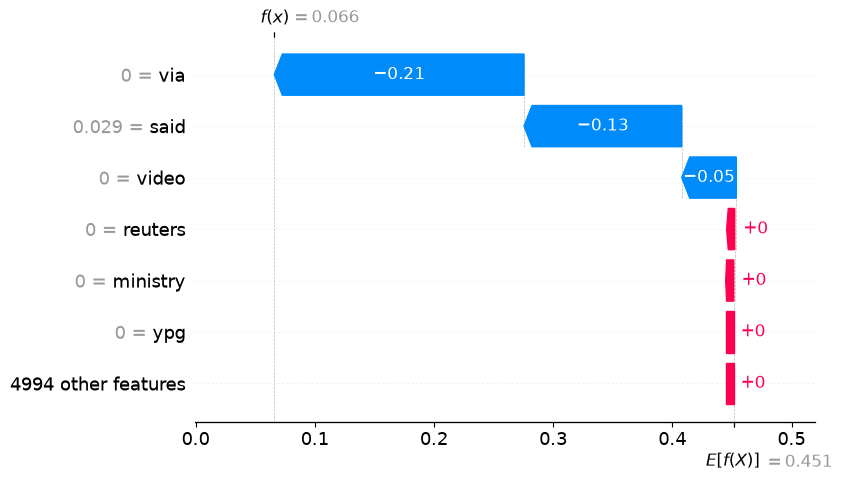

In [21]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at 0.451, the tree's average prediction, and ends at 0.066, the probability of the big real leaf. The bars add up exactly to the difference, which LIME doesn't guarantee.

The biggest push toward real is via (−0.21), even though the article doesn't contain it: having no photo credit is what sent it down the left branch. said comes next (−0.13), and the missing video adds −0.05. reuters and ministry add almost nothing, and the 4,995 terms the tree never uses add exactly zero.

LIME and SHAP agree that said is the active reason for the miss. SHAP adds what LIME can't show: the missing via matters even more. Both report the tree's path correctly.

### SHAP Waterfall (the other two articles)

To compare with LIME on all three articles, SHAP also explains the real article that was flagged and the fake article that was caught.

False Positive (real, flagged)


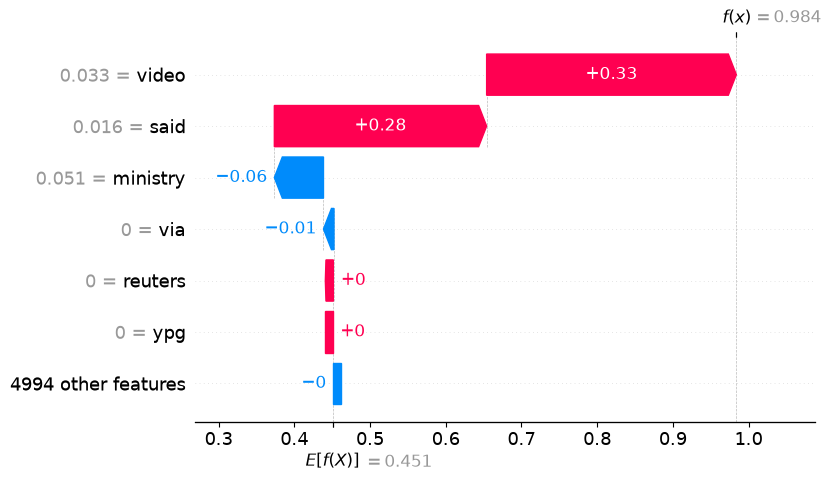

True Positive (fake, caught)


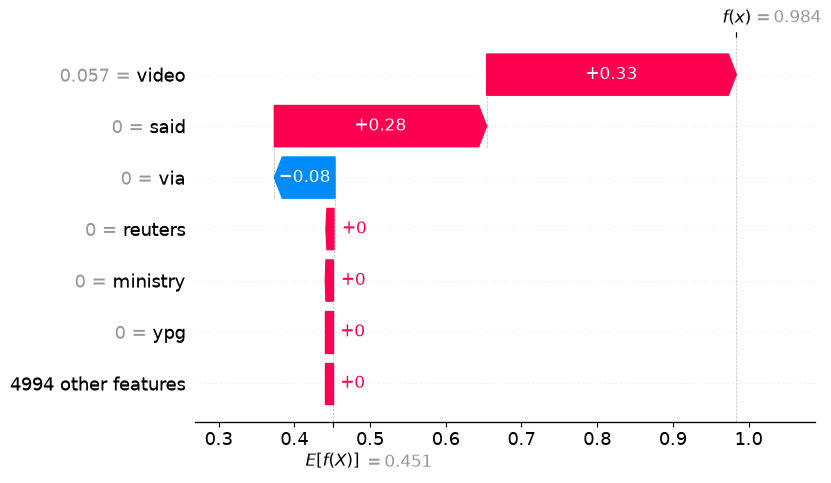

In [22]:
for name in ["False Positive (real, flagged)", "True Positive (fake, caught)"]:
    i = cases[name]
    x_one = X_test_dense[i:i + 1]

    sv_one = explainer_shap.shap_values(x_one, check_additivity=False)
    if isinstance(sv_one, list):
        sv_one = sv_one[1]
    elif np.ndim(sv_one) == 3:
        sv_one = sv_one[:, :, 1]

    print(name)
    shap.plots.waterfall(
        shap.Explanation(values=sv_one[0], base_values=base_value,
                         data=x_one[0], feature_names=list(feature_names)),
        max_display=7
    )

Both articles end at exactly the same score, 0.984: they fall into the same leaf of the tree, its most "fake" leaf. The tree has no way to tell them apart.

**Real article flagged (False Positive).** It contains "video", which adds +0.33 toward fake. It also contains "said", but only weakly (TF-IDF 0.016). That's below the tree's cut-off, so the tree treats it as if "said" were missing, and that adds another +0.28 toward fake. "ministry" pulls back slightly (−0.06), but not enough to change the leaf.

**Fake article caught (True Positive).** The same two words do the work: "video" is present (+0.33) and "said" is missing (+0.28). The only difference is that "via" is also missing, which counts slightly against fake (−0.08).

So the real article was flagged for the same reason the fake one was caught: it mentions a video and barely uses "said". With only five words to look at, the tree can't see anything else in the article. All 4,994 other words add exactly 0.

## 10. Summary

The decision tree (depth 3, at least 50 articles per leaf) is small enough to read and check by hand. It uses five terms: via, said, video, reuters and ministry.

Test accuracy is 0.883 and Fake-class recall 0.923, well above always predicting "real" (0.548) but below the baseline logistic regression (0.980 and 0.969). Deeper trees do better (0.943 at depth 10), so the shallow tree gives up about 6 points of accuracy to stay readable. Training and test recall are almost identical, so it isn't overfitting; it is just too simple.

The explanation methods match the tree's real rules:

- **PFI:** said and via matter most (recall drops of 0.085 and 0.052), and all five terms have clear effects.
- **TreeSHAP:** every unused term gets exactly zero, and via moves the probability most (0.22 on average), even when it's absent.
- **LIME:** each extreme prediction rests on one word (video or said), and a real article gets flagged with the same confidence as a correctly caught fake.
- **SHAP waterfall (missed fake):** the article has no "via", and SHAP shows that missing word pushed it toward real more than anything else. LIME can't show this, because it can only remove words that are there.
- **SHAP waterfall (flagged real and caught fake):** both articles contain "video" and barely use "said", so they land in the same leaf with the same score (0.984). The tree can't tell a real article from a fake one when they share those two words.

Since the methods report rules we can check correctly, we can trust them more on the Random Forest, where we can't.

The tree's most important question is whether an article contains via, a word from a photo credit on fake sites, not from anything the article says. A readable model makes that shortcut obvious. For a trust-and-safety reviewer, it isn't reliable: a fake article with no photo credit that quotes people like a news report gets labelled real.